# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


### Predicción inicial
Espero que las clases del dataset se encuentren desequilibradas, es decir que algunas especies de flores tengan más ejemplos que otras.
Creo que las medidas permitirán clasificar las flores al diferenciarlas por sus características similares.

In [3]:
from sklearn.datasets import load_iris
import pandas as pd
iris = load_iris()
x = iris.data
y = iris.target
df = pd.DataFrame(x, columns=[
    "largo_sepalo_cm",
    "ancho_sepalo_cm",
    "largo_petalo_cm",
    "ancho_petalo_cm",
])
df["especie"] = iris.target_names[y]


### ¿Qué representa cada instancia?

In [4]:
print(df.head(5))
print("Cada instancia representa las medidas de sépalo y pétalo de una flor junto con la especie a la que dicha flor pertenece.")

   largo_sepalo_cm  ancho_sepalo_cm  largo_petalo_cm  ancho_petalo_cm especie
0              5.1              3.5              1.4              0.2  setosa
1              4.9              3.0              1.4              0.2  setosa
2              4.7              3.2              1.3              0.2  setosa
3              4.6              3.1              1.5              0.2  setosa
4              5.0              3.6              1.4              0.2  setosa
Cada instancia representa las medidas de sépalo y pétalo de una flor junto con la especie a la que dicha flor pertenece.


### Número de instancias y características.

In [5]:
print("Número de instancias:",x.shape[0])
print("Número de caracteristicas:",x.shape[1])

Número de instancias: 150
Número de caracteristicas: 4


### Nombre y significado de cada característica.

In [6]:
print(iris.feature_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


Estas características hacen referencia a la longitud y ancho del sépalo en centímetros que es la parte que forman la parte más externa de la flor, también podemos encontrar la longitud y ancho de los pétalos en centímetros que son las hojas modificasdas que forman la corola de la flor.
A pesar de que los nombres se encuentran originalmente en inglés se las a cambiado a español en el DataFrame por facilidad de entendimiento.

### Clases y cantidad de ejemplos por clase.

In [7]:
print("Clases:", iris.target_names)
print(df["especie"].value_counts())

Clases: ['setosa' 'versicolor' 'virginica']
especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### Dimensiones de la matriz de características y del vector de etiquetas.

In [8]:
print("Dimensiones de la matriz de características X:",x.shape)
print("Dimensiones del vector de etiquetas y:",y.shape)

Dimensiones de la matriz de características X: (150, 4)
Dimensiones del vector de etiquetas y: (150,)


Por lo tanto la matriz de características tiene una dimensión de 150 filas y 4 columnas, mientras que el vector de etiquetas tiene una etiqueta de especie para las 150 flores

### Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.

In [9]:
df.head(5)


,largo_sepalo_cm,ancho_sepalo_cm,largo_petalo_cm,ancho_petalo_cm,especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


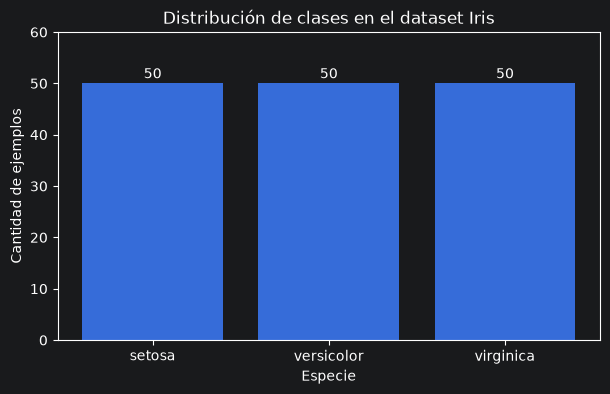

In [10]:
import matplotlib.pyplot as plt
conteo_clases = df["especie"].value_counts().reindex(iris.target_names)
plt.figure(figsize=(7, 4))
plt.bar(conteo_clases.index, conteo_clases.values)
plt.title("Distribución de clases en el dataset Iris")
plt.xlabel("Especie")
plt.ylabel("Cantidad de ejemplos")
plt.ylim(0, 60)
for posicion, cantidad in enumerate(conteo_clases.values):
    plt.text(posicion, cantidad + 1, str(cantidad), ha="center")
plt.show()

# 2. Comparación de clasificadores
## Predicciones iniciales
Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?
## Modelos
Construye un modelo de clasificación para la clase y compara:

* Gaussian Naive Bayes.
* Regresión logística multiclase.
* SVM lineal.
* Árbol de decisión.
* Random Forest.
* Gradient Boosting.
* MLP de clasificación.
* Usa características estandarizadas para los clasificadores.
## Procedimiento
Define configuraciones iniciales.
Entrena con la partición de entrenamiento.
Compara accuracy y F1 macro en validación.
Realiza ajustes limitados usando solamente validación.
Congela las configuraciones.
Evalúa todos los modelos finales sobre la misma partición de prueba.
La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados
Presenta una tabla con:

Modelo	Transformación	Hiperparámetros principales	Accuracy de prueba	F1 macro de prueba
Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación
1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

### Predicciones iniciales
1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
Creo que regresión logística, SVM lineal y MLP de clasificación son modelos sensibles a las escalas de las características.
La regresión logística funciona gracias a una combinación de las características a través de pesos por lo que las escalas de dichas características afectan directamente a la clase predicha
SVM lineal por su parte determina el hiperplano capaz de separar a las clases por lo que la escala de las características afecta directamente a la distancia entre el hiperplano determinado y el punto, afectando a la clasificación que el modelo realiza.
MLP ajusta sus pesos mediante descenso de graidente, si las entradas están en escalas distintas el entrenamiento puede ser menos estable.
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
Espero que el modelo de regresión logística multiclase sea el que produzca fornteras de decisión más simples dado que realiza separaciones lineales que son sencillas de interpretar.
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?
El rendimiento de un modelo depende de la data, de los patrones y relaciones entre las características y las clases, cada modelo representa los datos de una manera distinta y puede generalizar mejor o no la estimación de la clase a la que pertenece.
### Modelos

Dividimos la dara en entrenamiento, validación y prueba

In [11]:
from sklearn.model_selection import train_test_split
# 60 % entrenamiento
x_train, x_temp, y_train, y_temp = train_test_split(
    x,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)
# 20 % validación y 20 % prueba
x_val, x_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)
print("Entrenamiento:", x_train.shape, y_train.shape)
print("Validación:", x_val.shape, y_val.shape)
print("Prueba:", x_test.shape, y_test.shape)

Entrenamiento: (90, 4) (90,)
Validación: (30, 4) (30,)
Prueba: (30, 4) (30,)


#### Gaussian Naive Bayes


In [12]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score
modelo_gnb = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", GaussianNB())
])
modelo_gnb.fit(x_train, y_train)
pred_gnb_val = modelo_gnb.predict(x_val)

accuracy_gnb_val = accuracy_score(y_val, pred_gnb_val)
f1_gnb_val = f1_score(y_val, pred_gnb_val, average="macro")
print("Accuracy en validación:", accuracy_gnb_val)
print("F1 macro en validación:", f1_gnb_val)

Accuracy en validación: 0.9333333333333333
F1 macro en validación: 0.9333333333333332


#### Regresión logística multiclase

In [13]:
from sklearn.linear_model import LogisticRegression

modelo_logistico = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])
modelo_logistico.fit(x_train, y_train)
pred_logistica_val = modelo_logistico.predict(x_val)
accuracy_logistica_val = accuracy_score(y_val, pred_logistica_val)
f1_logistica_val = f1_score(
    y_val,
    pred_logistica_val,
    average="macro"
)

print("Accuracy en validación:", accuracy_logistica_val)
print("F1 macro en validación:", f1_logistica_val)

Accuracy en validación: 0.9333333333333333
F1 macro en validación: 0.9333333333333332


#### SVM lineal

In [14]:
from sklearn.svm import SVC

modelo_svm = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", SVC(
        kernel="linear",
        C=1.0
    ))
])
modelo_svm.fit(x_train, y_train)
pred_svm_val = modelo_svm.predict(x_val)
accuracy_svm_val = accuracy_score(y_val, pred_svm_val)
f1_svm_val = f1_score(
    y_val,
    pred_svm_val,
    average="macro"
)

print("Accuracy en validación:", accuracy_svm_val)
print("F1 macro en validación:", f1_svm_val)

Accuracy en validación: 0.9666666666666667
F1 macro en validación: 0.9665831244778612


#### Árbol de decisión

In [15]:
from sklearn.tree import DecisionTreeClassifier

modelo_arbol = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", DecisionTreeClassifier(
        random_state=42
    ))
])

modelo_arbol.fit(x_train, y_train)
pred_arbol_val = modelo_arbol.predict(x_val)

accuracy_arbol_val = accuracy_score(y_val, pred_arbol_val)
f1_arbol_val = f1_score(
    y_val,
    pred_arbol_val,
    average="macro"
)

print("Accuracy en validación:", accuracy_arbol_val)
print("F1 macro en validación:", f1_arbol_val)

Accuracy en validación: 0.9333333333333333
F1 macro en validación: 0.9333333333333332


#### Random forest

In [16]:
from sklearn.ensemble import RandomForestClassifier

modelo_random_forest = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])
modelo_random_forest.fit(x_train, y_train)
pred_rf_val = modelo_random_forest.predict(x_val)
accuracy_rf_val = accuracy_score(y_val, pred_rf_val)
f1_rf_val = f1_score(
    y_val,
    pred_rf_val,
    average="macro"
)

print("Accuracy en validación:", accuracy_rf_val)
print("F1 macro en validación:", f1_rf_val)

Accuracy en validación: 0.9333333333333333
F1 macro en validación: 0.9333333333333332


#### Gradient Boosting

In [17]:
from sklearn.ensemble import GradientBoostingClassifier

modelo_gradient_boosting = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", GradientBoostingClassifier(
        random_state=42
    ))
])
modelo_gradient_boosting.fit(x_train, y_train)
pred_gb_val = modelo_gradient_boosting.predict(x_val)
accuracy_gb_val = accuracy_score(y_val, pred_gb_val)
f1_gb_val = f1_score(
    y_val,
    pred_gb_val,
    average="macro"
)
print("Accuracy en validación:", accuracy_gb_val)
print("F1 macro en validación:", f1_gb_val)

Accuracy en validación: 0.9333333333333333
F1 macro en validación: 0.9333333333333332


#### MLP

In [18]:
from sklearn.neural_network import MLPClassifier

modelo_mlp = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", MLPClassifier(
        hidden_layer_sizes=(10,),
        max_iter=2000,
        random_state=42
    ))
])
modelo_mlp.fit(x_train, y_train)
pred_mlp_val = modelo_mlp.predict(x_val)
accuracy_mlp_val = accuracy_score(y_val, pred_mlp_val)
f1_mlp_val = f1_score(
    y_val,
    pred_mlp_val,
    average="macro"
)
print("Accuracy en validación:", accuracy_mlp_val)
print("F1 macro en validación:", f1_mlp_val)

Accuracy en validación: 0.9666666666666667
F1 macro en validación: 0.9665831244778612


### Comparación

### Ajuste limitado de hiperparámetros

A continuación se comparan pocas configuraciones por modelo. Cada
configuración se entrena únicamente con el conjunto de entrenamiento y
se selecciona según el mayor F1 macro en validación. El conjunto de
prueba permanece reservado y no se utiliza en esta etapa.

In [42]:
from sklearn.base import clone
from sklearn.model_selection import ParameterGrid

# Una cantidad limitada de configuraciones por modelo
candidatos = {
    "Gaussian Naive Bayes": {
        "pipeline": Pipeline([
            ("escalador", StandardScaler()),
            ("clasificador", GaussianNB())
        ]),
        "parametros": {
            "clasificador__var_smoothing": [1e-9, 1e-7, 1e-5]
        }
    },

    "Regresión logística": {
        "pipeline": Pipeline([
            ("escalador", StandardScaler()),
            ("clasificador", LogisticRegression(
                max_iter=2000,
                random_state=42
            ))
        ]),
        "parametros": {
            "clasificador__C": [0.1, 1, 10]
        }
    },

    "SVM lineal": {
        "pipeline": Pipeline([
            ("escalador", StandardScaler()),
            ("clasificador", SVC(kernel="linear"))
        ]),
        "parametros": {
            "clasificador__C": [0.1, 1, 10]
        }
    },

    "Árbol de decisión": {
        "pipeline": Pipeline([
            ("escalador", StandardScaler()),
            ("clasificador", DecisionTreeClassifier(random_state=42))
        ]),
        "parametros": {
            "clasificador__max_depth": [2, 3, None]
        }
    },

    "Random Forest": {
        "pipeline": Pipeline([
            ("escalador", StandardScaler()),
            ("clasificador", RandomForestClassifier(random_state=42))
        ]),
        "parametros": {
            "clasificador__n_estimators": [100, 200],
            "clasificador__max_depth": [2, 3, None]
        }
    },

    "Gradient Boosting": {
        "pipeline": Pipeline([
            ("escalador", StandardScaler()),
            ("clasificador", GradientBoostingClassifier(random_state=42))
        ]),
        "parametros": {
            "clasificador__n_estimators": [50, 100],
            "clasificador__max_depth": [1, 2]
        }
    },

    "MLP": {
        "pipeline": Pipeline([
            ("escalador", StandardScaler()),
            ("clasificador", MLPClassifier(
                max_iter=3000,
                random_state=42
            ))
        ]),
        "parametros": {
            "clasificador__hidden_layer_sizes": [(5,), (10,), (20,)]
        }
    }
}

resultados_ajuste = []
configuraciones_congeladas = {}

for nombre, especificacion in candidatos.items():
    mejor_f1 = -1
    mejor_accuracy = -1
    mejores_parametros = None

    for parametros in ParameterGrid(especificacion["parametros"]):
        modelo = clone(especificacion["pipeline"])
        modelo.set_params(**parametros)

        modelo.fit(x_train, y_train)

        pred_val = modelo.predict(x_val)
        accuracy_val = accuracy_score(y_val, pred_val)
        f1_val = f1_score(y_val, pred_val, average="macro")

        parametros_limpios = {
            clave.replace("clasificador__", ""): valor
            for clave, valor in parametros.items()
        }

        resultados_ajuste.append({
            "Modelo": nombre,
            "Hiperparámetros": str(parametros_limpios),
            "Accuracy validación": accuracy_val,
            "F1 macro validación": f1_val
        })

        if (f1_val > mejor_f1 or
                (f1_val == mejor_f1 and accuracy_val > mejor_accuracy)):
            mejor_f1 = f1_val
            mejor_accuracy = accuracy_val
            mejores_parametros = parametros

    configuraciones_congeladas[nombre] = mejores_parametros

tabla_ajustes = pd.DataFrame(resultados_ajuste)
tabla_ajustes.sort_values(
    by=["Modelo", "F1 macro validación", "Accuracy validación"],
    ascending=[True, False, False]
)|

,Modelo,Hiperparámetros,Accuracy validación,F1 macro validación
0,Gaussian Naive Bayes,{'var_smoothing': 1e-09},0.933333,0.933333
1,Gaussian Naive Bayes,{'var_smoothing': 1e-07},0.933333,0.933333
2,Gaussian Naive Bayes,{'var_smoothing': 1e-05},0.933333,0.933333
20,Gradient Boosting,"{'max_depth': 2, 'n_estimators': 50}",0.966667,0.966583
18,Gradient Boosting,"{'max_depth': 1, 'n_estimators': 50}",0.933333,0.933333
19,Gradient Boosting,"{'max_depth': 1, 'n_estimators': 100}",0.933333,0.933333
21,Gradient Boosting,"{'max_depth': 2, 'n_estimators': 100}",0.933333,0.933333
22,MLP,"{'hidden_layer_sizes': (5,)}",0.966667,0.966583
23,MLP,"{'hidden_layer_sizes': (10,)}",0.966667,0.966583
24,MLP,"{'hidden_layer_sizes': (20,)}",0.966667,0.966583


In [43]:
tabla_configuraciones = pd.DataFrame([
    {
        "Modelo": nombre,
        "Hiperparámetros congelados": str({
            clave.replace("clasificador__", ""): valor
            for clave, valor in parametros.items()
        })
    }
    for nombre, parametros in configuraciones_congeladas.items()
])

tabla_configuraciones

,Modelo,Hiperparámetros congelados
0,Gaussian Naive Bayes,{'var_smoothing': 1e-09}
1,Regresión logística,{'C': 1}
2,SVM lineal,{'C': 1}
3,Árbol de decisión,{'max_depth': 3}
4,Random Forest,"{'max_depth': 2, 'n_estimators': 100}"
5,Gradient Boosting,"{'max_depth': 2, 'n_estimators': 50}"
6,MLP,"{'hidden_layer_sizes': (5,)}"


### Evaluación final en prueba

A continuación, cada modelo se ajusta con entrenamiento usando su
configuración congelada y se evalúa una sola vez sobre la misma
partición de prueba.

In [44]:
def formatear_parametros(parametros):
    parametros_limpios = {
        clave.replace("clasificador__", ""): valor
        for clave, valor in parametros.items()
    }
    return str(parametros_limpios)

modelos_finales = {}
predicciones_prueba_clasificacion = {}
resultados_prueba_clasificacion = []

for nombre, especificacion in candidatos.items():
    modelo_final = clone(especificacion["pipeline"])
    modelo_final.set_params(**configuraciones_congeladas[nombre])

    # Entrenar con entrenamiento; no se ajusta nada con prueba
    modelo_final.fit(x_train, y_train)

    # Evaluación final única sobre prueba
    pred_test = modelo_final.predict(x_test)

    modelos_finales[nombre] = modelo_final
    predicciones_prueba_clasificacion[nombre] = pred_test

    resultados_prueba_clasificacion.append({
        "Modelo": nombre,
        "Transformación": "StandardScaler",
        "Hiperparámetros principales": formatear_parametros(
            configuraciones_congeladas[nombre]
        ),
        "Accuracy de prueba": accuracy_score(y_test, pred_test),
        "F1 macro de prueba": f1_score(
            y_test,
            pred_test,
            average="macro"
        )
    })

tabla_prueba_clasificacion = pd.DataFrame(
    resultados_prueba_clasificacion
)

tabla_prueba_clasificacion.sort_values(
    by="F1 macro de prueba",
    ascending=False
).reset_index(drop=True)

,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Árbol de decisión,StandardScaler,{'max_depth': 3},1.000000,1.000000
1,MLP,StandardScaler,"{'hidden_layer_sizes': (5,)}",1.000000,1.000000
2,Random Forest,StandardScaler,"{'max_depth': 2, 'n_estimators': 100}",0.966667,0.966583
3,Gradient Boosting,StandardScaler,"{'max_depth': 2, 'n_estimators': 50}",0.966667,0.966583
4,SVM lineal,StandardScaler,{'C': 1},0.933333,0.932660
5,Gaussian Naive Bayes,StandardScaler,{'var_smoothing': 1e-09},0.933333,0.932660
6,Regresión logística,StandardScaler,{'C': 1},0.933333,0.932660


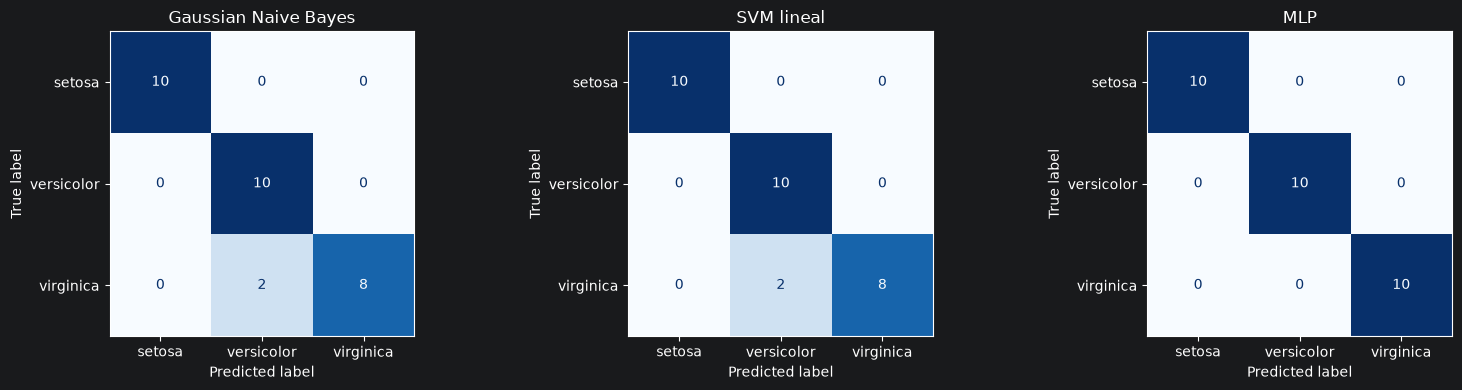

In [45]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

modelos_matrices = [
    "Gaussian Naive Bayes",
    "SVM lineal",
    "MLP"
]

figura, ejes = plt.subplots(1, 3, figsize=(16, 4))

for eje, nombre in zip(ejes, modelos_matrices):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicciones_prueba_clasificacion[nombre],
        labels=[0, 1, 2],
        display_labels=iris.target_names,
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=eje
    )
    eje.set_title(nombre)

plt.tight_layout()
plt.show()

## Interpretación
1. ¿Cuál fue el modelo con el mejor desempeño?
Los modelos con mejor desempeño fueron el árbol de desición y el MLP ambos con accuracy y F1 en pruebas de 1.00 sin embargo, se debe considerar que debido al tamaño del dataset pruebas tiene únicamente 30 observaciones por lo que no es un resultado confiable.
2. ¿Cuál fue el modelo más sencillo de programar?
El modelo más sencillo de programar fue Gaussian Naive Bayes dado que requiere de pocos hiperparámetros y se construye directamente con la llamada a la librería correspondiente.
3. ¿Accuracy y F1 macro cuentan la misma historia?
Aunque ambos se utilizan para medir el rendimiento de un modelo accuracy mide la proporción de predicciones correctas que realizó el modelo mientras que F1 macro evalúa el equilibrio entre precisión y el recall.
4. ¿Cuál es la diferencia entre las métricas macro y micro?
Las métricas macro evalúa el rendimiento dando el mismo peso a cada categoría o clase, mientras que micro evalúa el rendimiento dando el mismo peso a cada muestra.
5. ¿Qué aporta el MLP frente a un modelo lineal?
MLP es capaz de aprender relaciones no lineales entre características lo cual aumenta la complejidad del modelo pero también aumenta su capacidad de estimación frente a un modelo lineal que asume una relación lineal entre las características.



In [46]:
nombre_modelo_errores = "Gaussian Naive Bayes"

predicciones_error = predicciones_prueba_clasificacion[
    nombre_modelo_errores
]

indices_error = np.where(y_test != predicciones_error)[0]

errores_clasificacion = pd.DataFrame(
    x_test[indices_error],
    columns=iris.feature_names
)

errores_clasificacion.insert(
    0,
    "Clase real",
    iris.target_names[y_test[indices_error]]
)

errores_clasificacion.insert(
    1,
    "Clase predicha",
    iris.target_names[predicciones_error[indices_error]]
)

errores_clasificacion

,Clase real,Clase predicha,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,virginica,versicolor,6.1,2.6,5.6,1.4
1,virginica,versicolor,6.3,2.8,5.1,1.5


### Análisis de errores de clasificación

Los dos errores seleccionados pertenecen a flores cuya clase real es
virginica, pero Gaussian Naive Bayes las predijo como versicolor. Esto
indica que, según sus medidas de sépalo y pétalo, estos ejemplos se
parecen a observaciones de versicolor para este modelo.

Se puede concluir que existe solapamiento entre las características de
algunas flores versicolor y virginica, o que el supuesto de
independencia de Gaussian Naive Bayes no representa completamente la
relación entre las medidas.


# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

### Cargar dataset Diabetes

In [20]:
from sklearn.datasets import load_diabetes
import pandas as pd
diabetes = load_diabetes()

x_diabetes = diabetes.data
y_diabetes = diabetes.target

df_diabetes = pd.DataFrame(
    x_diabetes,
    columns=diabetes.feature_names
)
df_diabetes["progresion_enfermedad"] = y_diabetes
print("Dimensiones de x:", x_diabetes.shape)
print("Dimensiones de y:", y_diabetes.shape)
print("\nCaracterísticas:")
print(diabetes.feature_names)
df_diabetes.head()

Dimensiones de x: (442, 10)
Dimensiones de y: (442,)

Características:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progresion_enfermedad
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


### Predicción inicial
¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.
Espero que un modelo más flexible produzca una menor cantidad de errores ante datos nuevos, sin embargo no siempre, un modelo extremadamente flexible causará overfitting por lo que fallaría en generalizar y por ende se espera falle al ingresar nuevos datos.
### Modelos

Divido el dataset en entrenamiento, validación y pruebas.

In [21]:
from sklearn.model_selection import train_test_split
# 60 % entrenamiento
x_train_reg, x_temp_reg, y_train_reg, y_temp_reg = train_test_split(
    x_diabetes,
    y_diabetes,
    test_size=0.40,
    random_state=42
)
#20 % validación y 20 % prueba
x_val_reg, x_test_reg, y_val_reg, y_test_reg = train_test_split(
    x_temp_reg,
    y_temp_reg,
    test_size=0.50,
    random_state=42
)

print("Entrenamiento:", x_train_reg.shape, y_train_reg.shape)
print("Validación:", x_val_reg.shape, y_val_reg.shape)
print("Prueba:", x_test_reg.shape, y_test_reg.shape)

Entrenamiento: (265, 10) (265,)
Validación: (88, 10) (88,)
Prueba: (89, 10) (89,)


#### Regresión lineal

In [26]:
modelo_lineal = Pipeline([
    ("escalador", StandardScaler()),
    ("regresor", LinearRegression())
])

modelo_lineal.fit(x_train_reg, y_train_reg)
pred_lineal_val = modelo_lineal.predict(x_val_reg)

mae_lineal_val = mean_absolute_error(y_val_reg, pred_lineal_val)
rmse_lineal_val = np.sqrt(
    mean_squared_error(y_val_reg, pred_lineal_val)
)
r2_lineal_val = r2_score(y_val_reg, pred_lineal_val)

print("MAE en validación:", mae_lineal_val)
print("RMSE en validación:", rmse_lineal_val)
print("R² en validación:", r2_lineal_val)

MAE en validación: 38.22127405114379
RMSE en validación: 49.14969247001349
R² en validación: 0.5809667034070141


#### Ridge

In [27]:
from sklearn.linear_model import Ridge

resultados_ridge = []

for alpha in [0.01, 0.1, 1, 10, 100]:
    modelo_ridge = Pipeline([
        ("escalador", StandardScaler()),
        ("regresor", Ridge(alpha=alpha))
    ])

    modelo_ridge.fit(x_train_reg, y_train_reg)

    pred_ridge_train = modelo_ridge.predict(x_train_reg)
    pred_ridge_val = modelo_ridge.predict(x_val_reg)

    coeficientes = modelo_ridge.named_steps["regresor"].coef_

    resultados_ridge.append({
        "alpha": alpha,
        "RMSE entrenamiento": np.sqrt(
            mean_squared_error(y_train_reg, pred_ridge_train)
        ),
        "RMSE validación": np.sqrt(
            mean_squared_error(y_val_reg, pred_ridge_val)
        ),
        "Magnitud de coeficientes (norma L2)": np.linalg.norm(coeficientes)
    })

tabla_ridge = pd.DataFrame(resultados_ridge)
tabla_ridge

,alpha,RMSE entrenamiento,RMSE validación,Magnitud de coeficientes (norma L2)
0,0.01,54.284932,49.150290,57.846830
1,0.10,54.285138,49.155640,56.892488
2,1.00,54.296591,49.203254,50.572324
3,10.00,54.395081,49.373137,41.089862
4,100.00,55.440133,50.814869,31.934667


#### Lasso

In [29]:
from sklearn.linear_model import Lasso

resultados_lasso = []

for alpha in [0.01, 0.1, 1, 10, 100]:
    modelo_lasso = Pipeline([
        ("escalador", StandardScaler()),
        ("regresor", Lasso(
            alpha=alpha,
            max_iter=10000
        ))
    ])
    modelo_lasso.fit(x_train_reg, y_train_reg)

    pred_lasso_train = modelo_lasso.predict(x_train_reg)
    pred_lasso_val = modelo_lasso.predict(x_val_reg)

    coeficientes = modelo_lasso.named_steps["regresor"].coef_
    cantidad_ceros = np.sum(coeficientes == 0)

    resultados_lasso.append({
        "alpha": alpha,
        "RMSE entrenamiento": np.sqrt(
            mean_squared_error(y_train_reg, pred_lasso_train)
        ),
        "RMSE validación": np.sqrt(
            mean_squared_error(y_val_reg, pred_lasso_val)
        ),
        "Magnitud de coeficientes (norma L2)": np.linalg.norm(coeficientes),
        "Coeficientes nulos": cantidad_ceros
    })

tabla_lasso = pd.DataFrame(resultados_lasso)
tabla_lasso

,alpha,RMSE entrenamiento,RMSE validación,Magnitud de coeficientes (norma L2),Coeficientes nulos
0,0.01,54.285308,49.157489,56.556219,0
1,0.10,54.302324,49.203630,49.262947,0
2,1.00,54.473344,49.525358,41.094698,2
3,10.00,57.386437,53.820902,30.819244,6
4,100.00,77.330772,76.161364,0.000000,10


#### kNN de regresión

In [31]:
from sklearn.neighbors import KNeighborsRegressor

resultados_knn = []

for k in [3, 5, 9, 15, 25]:
    modelo_knn = Pipeline([
        ("escalador", StandardScaler()),
        ("regresor", KNeighborsRegressor(
            n_neighbors=k
        ))
    ])

    # Entrenar con entrenamiento
    modelo_knn.fit(x_train_reg, y_train_reg)

    # Predecir en entrenamiento y validación
    pred_knn_train = modelo_knn.predict(x_train_reg)
    pred_knn_val = modelo_knn.predict(x_val_reg)

    resultados_knn.append({
        "Número de vecinos (k)": k,
        "RMSE entrenamiento": np.sqrt(
            mean_squared_error(y_train_reg, pred_knn_train)
        ),
        "RMSE validación": np.sqrt(
            mean_squared_error(y_val_reg, pred_knn_val)
        )
    })

tabla_knn = pd.DataFrame(resultados_knn)
tabla_knn

,Número de vecinos (k),RMSE entrenamiento,RMSE validación
0,3,45.173237,56.787138
1,5,52.473689,57.707007
2,9,54.527892,54.674806
3,15,55.803921,55.877450
4,25,58.073406,54.884003


#### Árbol de regresión

In [33]:
from sklearn.tree import DecisionTreeRegressor

resultados_arbol_reg = []

for profundidad in [2, 3, 4, 5, None]:
    modelo_arbol_reg = Pipeline([
        ("escalador", StandardScaler()),
        ("regresor", DecisionTreeRegressor(
            max_depth=profundidad,
            random_state=42
        ))
    ])

    # Ajustar solo con entrenamiento
    modelo_arbol_reg.fit(x_train_reg, y_train_reg)

    # Predecir en entrenamiento y validación
    pred_arbol_train = modelo_arbol_reg.predict(x_train_reg)
    pred_arbol_val = modelo_arbol_reg.predict(x_val_reg)

    resultados_arbol_reg.append({
        "Profundidad máxima": profundidad,
        "RMSE entrenamiento": np.sqrt(
            mean_squared_error(y_train_reg, pred_arbol_train)
        ),
        "RMSE validación": np.sqrt(
            mean_squared_error(y_val_reg, pred_arbol_val)
        )
    })

tabla_arbol_reg = pd.DataFrame(resultados_arbol_reg)
tabla_arbol_reg

,Profundidad máxima,RMSE entrenamiento,RMSE validación
0,2.0,57.698662,56.348158
1,3.0,52.739883,58.089879
2,4.0,47.637824,61.250357
3,5.0,41.113456,61.889490
4,NaN,0.000000,77.105153


#### Random forest

In [34]:
from sklearn.ensemble import RandomForestRegressor

resultados_rf_reg = []

for profundidad in [2, 3, 5, None]:
    modelo_rf_reg = Pipeline([
        ("escalador", StandardScaler()),
        ("regresor", RandomForestRegressor(
            n_estimators=200,
            max_depth=profundidad,
            random_state=42
        ))
    ])

    modelo_rf_reg.fit(x_train_reg, y_train_reg)
    pred_rf_train = modelo_rf_reg.predict(x_train_reg)
    pred_rf_val = modelo_rf_reg.predict(x_val_reg)

    resultados_rf_reg.append({
        "Profundidad máxima": profundidad,
        "RMSE entrenamiento": np.sqrt(
            mean_squared_error(y_train_reg, pred_rf_train)
        ),
        "RMSE validación": np.sqrt(
            mean_squared_error(y_val_reg, pred_rf_val)
        )
    })

tabla_rf_reg = pd.DataFrame(resultados_rf_reg)
tabla_rf_reg

,Profundidad máxima,RMSE entrenamiento,RMSE validación
0,2.0,54.264335,53.391403
1,3.0,49.413360,51.818814
2,5.0,37.654890,52.425151
3,NaN,22.387986,53.662556


#### Gradient Boosting

In [35]:
from sklearn.ensemble import GradientBoostingRegressor

resultados_gb_reg = []

for profundidad in [1, 2, 3]:
    modelo_gb_reg = Pipeline([
        ("escalador", StandardScaler()),
        ("regresor", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=profundidad,
            random_state=42
        ))
    ])
    modelo_gb_reg.fit(x_train_reg, y_train_reg)

    pred_gb_train = modelo_gb_reg.predict(x_train_reg)
    pred_gb_val = modelo_gb_reg.predict(x_val_reg)

    resultados_gb_reg.append({
        "Profundidad máxima": profundidad,
        "RMSE entrenamiento": np.sqrt(
            mean_squared_error(y_train_reg, pred_gb_train)
        ),
        "RMSE validación": np.sqrt(
            mean_squared_error(y_val_reg, pred_gb_val)
        )
    })

tabla_gb_reg = pd.DataFrame(resultados_gb_reg)
tabla_gb_reg

,Profundidad máxima,RMSE entrenamiento,RMSE validación
0,1,49.488831,50.212739
1,2,39.049810,52.404310
2,3,26.766485,53.980595


#### MLP de regresión

In [36]:
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor

resultados_mlp_reg = []

for capas in [(5,), (10,), (20,), (10, 10)]:
    modelo_mlp_reg = Pipeline([
        ("escalador_x", StandardScaler()),
        ("regresor", TransformedTargetRegressor(
            regressor=MLPRegressor(
                hidden_layer_sizes=capas,
                alpha=0.001,
                max_iter=3000,
                random_state=42
            ),
            transformer=StandardScaler()
        ))
    ])
    modelo_mlp_reg.fit(x_train_reg, y_train_reg)
    pred_mlp_train = modelo_mlp_reg.predict(x_train_reg)
    pred_mlp_val = modelo_mlp_reg.predict(x_val_reg)

    resultados_mlp_reg.append({
        "Capas ocultas": str(capas),
        "RMSE entrenamiento": np.sqrt(
            mean_squared_error(y_train_reg, pred_mlp_train)
        ),
        "RMSE validación": np.sqrt(
            mean_squared_error(y_val_reg, pred_mlp_val)
        )
    })

tabla_mlp_reg = pd.DataFrame(resultados_mlp_reg)
tabla_mlp_reg

,Capas ocultas,RMSE entrenamiento,RMSE validación
0,"(5,)",54.487749,50.580893
1,"(10,)",51.340308,53.428922
2,"(20,)",44.755433,55.537157
3,"(10, 10)",43.422356,55.337049


#### Resultados

In [38]:

x_ajuste_final = np.vstack([x_train_reg, x_val_reg])
y_ajuste_final = np.concatenate([y_train_reg, y_val_reg])

modelos_finales = {
    "Regresión lineal": Pipeline([
        ("escalador", StandardScaler()),
        ("regresor", LinearRegression())
    ]),

    "Ridge": Pipeline([
        ("escalador", StandardScaler()),
        ("regresor", Ridge(alpha=0.01))
    ]),

    "Lasso": Pipeline([
        ("escalador", StandardScaler()),
        ("regresor", Lasso(alpha=0.01, max_iter=10000))
    ]),

    "kNN": Pipeline([
        ("escalador", StandardScaler()),
        ("regresor", KNeighborsRegressor(n_neighbors=9))
    ]),

    "Árbol de regresión": Pipeline([
        ("escalador", StandardScaler()),
        ("regresor", DecisionTreeRegressor(
            max_depth=2,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("escalador", StandardScaler()),
        ("regresor", RandomForestRegressor(
            n_estimators=200,
            max_depth=3,
            random_state=42
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("escalador", StandardScaler()),
        ("regresor", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=1,
            random_state=42
        ))
    ]),

    "MLP": Pipeline([
        ("escalador_x", StandardScaler()),
        ("regresor", TransformedTargetRegressor(
            regressor=MLPRegressor(
                hidden_layer_sizes=(5,),
                alpha=0.001,
                max_iter=3000,
                random_state=42
            ),
            transformer=StandardScaler()
        ))
    ])
}

resultados_prueba = []
predicciones_prueba = {}

for nombre, modelo in modelos_finales.items():
    modelo.fit(x_ajuste_final, y_ajuste_final)
    pred_test = modelo.predict(x_test_reg)
    predicciones_prueba[nombre] = pred_test

    resultados_prueba.append({
        "Modelo": nombre,
        "MAE": mean_absolute_error(y_test_reg, pred_test),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, pred_test)),
        "R²": r2_score(y_test_reg, pred_test)
    })

tabla_prueba = pd.DataFrame(resultados_prueba)
tabla_prueba.sort_values(by="RMSE").reset_index(drop=True)

,Modelo,MAE,RMSE,R²
0,Random Forest,45.122285,55.379152,0.469817
1,Gradient Boosting,45.533714,55.402527,0.469369
2,MLP,45.317215,55.532335,0.466880
3,Regresión lineal,46.676708,56.647727,0.445249
4,Ridge,46.677311,56.648832,0.445227
5,Lasso,46.685281,56.664918,0.444912
6,kNN,45.722846,57.623912,0.425965
7,Árbol de regresión,49.685227,62.824063,0.317685


Random forest es el modelo con el menor error cuadrático seguido de forma cercana por Gradient Boosting y MLP

#### Gráficos

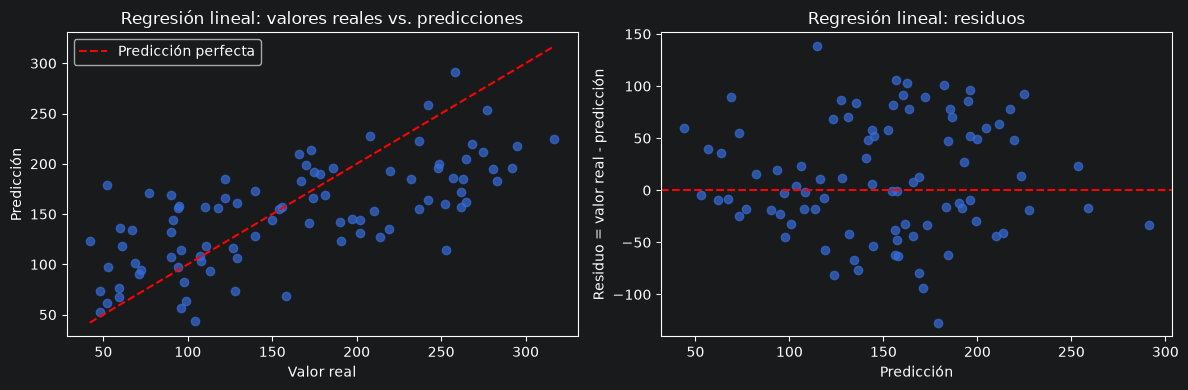

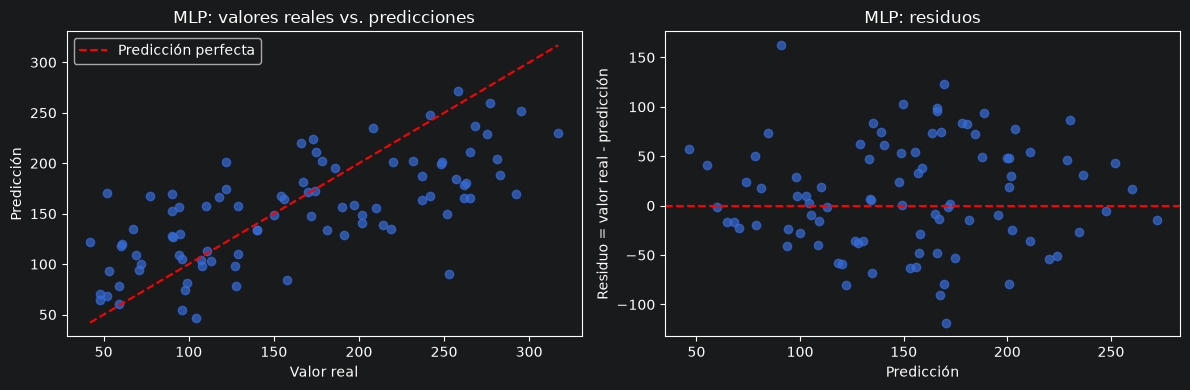

In [40]:

def graficar_resultados_regresion(nombre_modelo):
    predicciones = predicciones_prueba[nombre_modelo]
    residuos = y_test_reg - predicciones

    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

    # Valores reales frente a predicciones
    limite_min = min(y_test_reg.min(), predicciones.min())
    limite_max = max(y_test_reg.max(), predicciones.max())

    ejes[0].scatter(y_test_reg, predicciones, alpha=0.7)
    ejes[0].plot(
        [limite_min, limite_max],
        [limite_min, limite_max],
        color="red",
        linestyle="--",
        label="Predicción perfecta"
    )
    ejes[0].set_title(f"{nombre_modelo}: valores reales vs. predicciones")
    ejes[0].set_xlabel("Valor real")
    ejes[0].set_ylabel("Predicción")
    ejes[0].legend()

    # Residuos
    ejes[1].scatter(predicciones, residuos, alpha=0.7)
    ejes[1].axhline(0, color="red", linestyle="--")
    ejes[1].set_title(f"{nombre_modelo}: residuos")
    ejes[1].set_xlabel("Predicción")
    ejes[1].set_ylabel("Residuo = valor real - predicción")

    plt.tight_layout()
    plt.show()

graficar_resultados_regresion("Regresión lineal")
graficar_resultados_regresion("MLP")

tanto regresión lineal como MLP son capaces de encontrar relaciones entre las características y la progresión de la enfermedad sin embargo, ninguno logra realizar una predicción perfecta en el caso de la regresión lineal varios puntos se encuentran entre las predicciones de 120 y 200 acercando las predicciones al promedio, MLP por su parte no presenta un comportamiento de acercar al promedio pero genera también errores considerables.

#### Ejemplos

In [41]:
def obtener_errores_grandes(nombre_modelo):
    predicciones = predicciones_prueba[nombre_modelo]
    errores_absolutos = np.abs(y_test_reg - predicciones)

    indices = np.argsort(errores_absolutos)[-2:][::-1]

    ejemplos = pd.DataFrame(
        x_test_reg[indices],
        columns=diabetes.feature_names
    )

    ejemplos.insert(0, "Índice en prueba", indices)
    ejemplos["Valor real"] = y_test_reg[indices]
    ejemplos["Predicción"] = predicciones[indices]
    ejemplos["Error absoluto"] = errores_absolutos[indices]

    return ejemplos

errores_lineal = obtener_errores_grandes("Regresión lineal")
errores_mlp = obtener_errores_grandes("MLP")

print("Dos errores absolutos grandes: regresión lineal")
display(errores_lineal)

print("Dos errores absolutos grandes: MLP")
display(errores_mlp)

Dos errores absolutos grandes: regresión lineal


,Índice en prueba,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Valor real,Predicción,Error absoluto
0,39,0.041708,0.050680,-0.038540,0.052858,0.076860,0.116430,-0.039719,0.071210,-0.022517,-0.013504,253.0,114.69477,138.30523
1,8,0.016281,-0.044642,0.026128,0.058608,-0.060735,-0.044215,-0.013948,-0.033958,-0.051404,-0.025930,52.0,179.14039,127.14039


Dos errores absolutos grandes: MLP


,Índice en prueba,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Valor real,Predicción,Error absoluto
0,39,0.041708,0.05068,-0.038540,0.052858,0.07686,0.116430,-0.039719,0.071210,-0.022517,-0.013504,253.0,90.652695,162.347305
1,48,-0.034575,0.05068,-0.000817,0.070072,0.03971,0.066952,-0.065491,0.108111,0.026717,0.073480,292.0,169.292066,122.707934


En el caso de la regresión lineal el paciente con índice 39 tuvo un valor de 253 mientras que la predicción fue de 114.69 dando como resultado un error absoluto de 138.31, en el segundo caso el valor real era de 52 y obtuvo una predicción de 179.14 con un error absoluto de 127.14 por lo que en el primer caso se predijo un valor menor al real mientras que en el otro superior.
Para MLP el paciente de índice 39 tuvo también una predicción errónea esta vez de 90.65 con un error absoluto de 162.35 mayor al producido por regresión lineal en el mismo caso, el segundo error grande tenía un valor de 292 y obtuvo una predicción de 169.29 con error absoluto de 122.71.
Ambos modelos tienen dificultades para predecir ciertos valores extremos requiriendo de una mayor cantidad de datos para reducir los errores relacionados a estos casos.

#### Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
El modelo con mejor desempeño fue Random Forest con un RMSE de 55.38, Mae 45.12 y R² 0.470, seguido muy cercanamente por gradient boosting.
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
Esto se debe al comportamiento de estas medidas RMSE eleva los errores al cuadrado antes de promediarlos, penalizando más los errores grandes, por su lado MAE trata los errores de forma proporcional.
3. ¿Cómo se interpreta un R² negativo?
Significa que el modelo predice peor que un modelo que siempre predice el promedio del objetivo en los datos de prueba.
4. ¿Qué efecto tuvo aumentar la regularización?
Aumentar la regularización de Ridge y Lasso produce una reducción en los coeficientes, de modo que al aumentarlas lo suficiente algunos coeficientes se reducen a cero y en este caso aumentan el error.
5. ¿Qué puede explicar los errores grandes?
Estos errores se pueden dar por variables relevantes que no se encuentran en el dataset, además pueden existir relaciones complejas entre las variables que los modelos no son capaces de predecir lo cual junto con posible ruido o incertidumbre en las mediciones dan lugar a estos resultados.
6. ¿Un coeficiente predictivo demuestra una relación causal?
Un coeficiente predictivo simplemente indica que una característica es relevante para obtener una predicción, pero no es una prueba de relación causal.

# Declaración de uso de IA generativa

Para desarrollar este trabajo utilicé ChatGPT (OpenAI)como apoyo
pedagógico y asistente de programación. La IA se usó para aclarar
conceptos de Machine Learning, comprender el código,  y revisar la interpretación de métricas y resultados.

No utilicé las respuestas de forma automática. Ejecuté el código en mi
entorno, observé los resultados obtenidos y adapté las explicaciones al
notebook. La elección de configuraciones se realizó mediante los datos
de validación, y la evaluación final se hizo con el conjunto de prueba
reservado.

## Prompts utilizados

Los siguientes prompts representan ejemplos de las consultas realizadas
durante el desarrollo:

1. **Comprensión de datos y estructuras**

   > Estoy trabajando con el dataset Iris de scikit-learn. Explícame,
   > con ejemplos sencillos, qué contiene `iris.data`, qué representa
   > `iris.target` y cuál es la diferencia entre una matriz de
   > características y un vector de etiquetas. No resuelvas toda la
   > actividad; quiero comprender cada parte antes de continuar.

2. **Preparación del experimento de clasificación**

   > Estoy realizando una comparación de clasificadores con Iris.
   > Necesito separar los datos en entrenamiento, validación y prueba.
   > Propón código con `train_test_split`, explica el propósito de cada
   > conjunto y justifica el uso de `stratify`. Usa una partición
   > reproducible y explica cómo evitar usar el conjunto de prueba
   > durante el ajuste de hiperparámetros.

3. **Escalamiento y pipelines**

   > Explícame qué significa que un modelo sea sensible a la escala de
   > las características. Relaciónalo con regresión logística, SVM y MLP,
   > y explica por qué conviene usar `Pipeline` con `StandardScaler`
   > evitando fuga de información entre entrenamiento, validación y
   > prueba.

4. **Interpretación de métricas de clasificación**

   > Obtuve valores de accuracy y F1 macro al evaluar varios
   > clasificadores. Explícame qué mide F1 macro, cómo se interpreta y
   > por qué puede diferir de accuracy, especialmente cuando las clases
   > están desequilibradas.

5. **Regularización en regresión**

   > Estoy comparando Ridge y Lasso en el dataset Diabetes. Ayúdame a
   > diseñar un experimento pequeño que compare varios valores de
   > `alpha` usando solamente entrenamiento y validación. Debe mostrar
   > error de entrenamiento, error de validación, magnitud de los
   > coeficientes y cantidad de coeficientes nulos en Lasso. Explica qué
   > conclusiones puedo obtener y cuáles no.

6. **Evaluación e interpretación de regresión**

   > Tengo resultados de MAE, RMSE y R² para varios modelos de regresión
   > sobre un conjunto de prueba reservado. Ayúdame a interpretar las
   > métricas sin afirmar causalidad. También explica cómo analizar un
   > gráfico de valores reales frente a predicciones y un gráfico de
   > residuos.

7. **Análisis crítico de errores**

   > Tengo dos observaciones con errores absolutos grandes en regresión
   > lineal y MLP. Ayúdame a redactar una interpretación basada en los
   > resultados, distinguiendo entre lo que sugieren los datos y lo que
   > no se puede concluir sobre causalidad o características individuales.
8. **Apoyo para implementar código**

   > Estoy realizando una práctica de Machine Learning con scikit-learn.
   > Ayúdame a escribir y explicar código Python paso a paso para
   > entrenar un modelo usando un `Pipeline`, evaluar sus predicciones
   > con las métricas adecuadas y guardar los resultados en una tabla.
   > Explica el propósito de cada bloque de código y asegúrate de usar
   > entrenamiento para ajustar, validación para seleccionar
   > hiperparámetros y prueba solo para la evaluación final.